# Rag From Scratch: Indexing

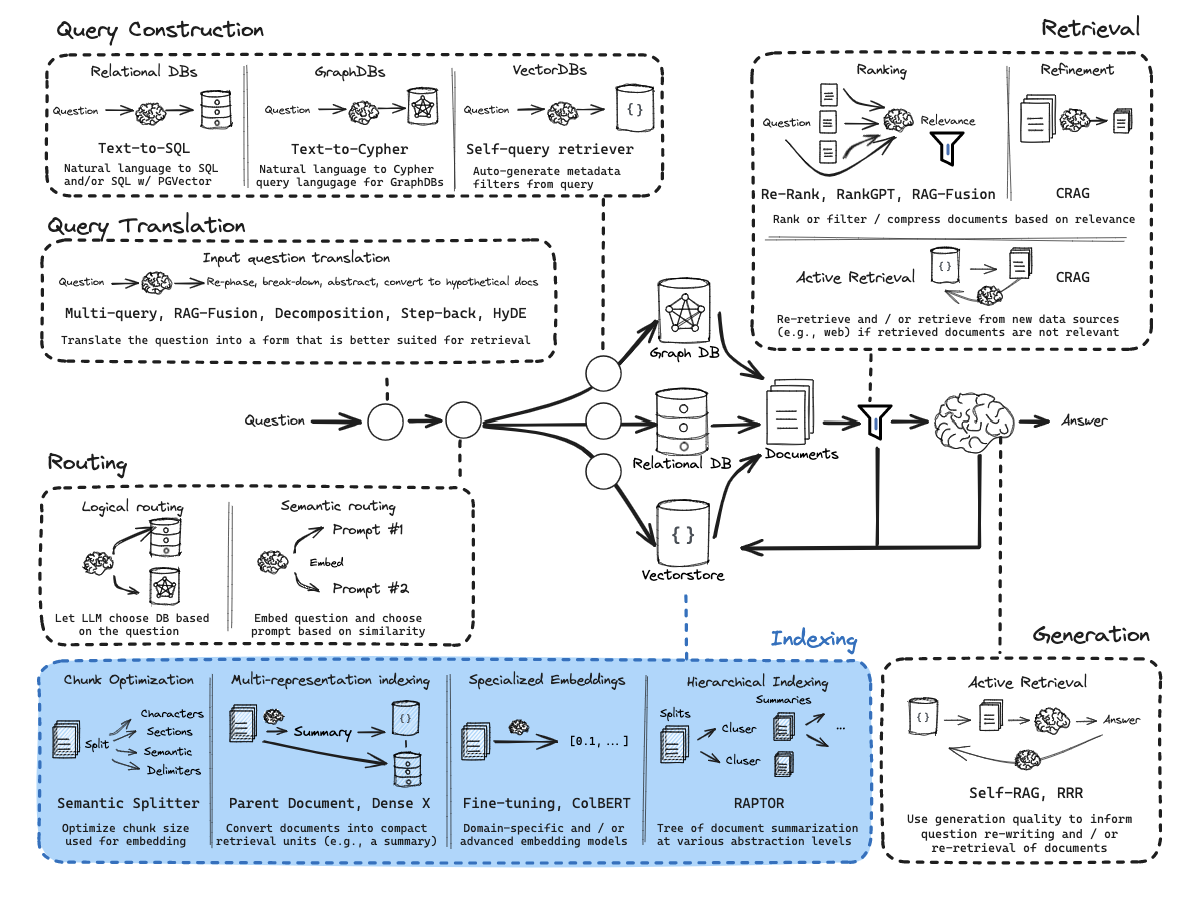
![alt text](4708ecf0-e07e-435a-b93f-fcd2f86d0491.png)


In [1]:
from rag_config import load_config, show_config

load_config()
show_config()  # Only show model names and whether a key is configured.


PARATERA_BASE_URL: https://llmapi.paratera.com/v1
PARATERA_CHAT_MODEL: Qwen3.8-Flash
PARATERA_EMBEDDING_MODEL: GLM-Embedding-3
PARATERA_API_KEY configured: True


## Part 12: Multi-representation Indexing  多表示索引

Flow: 

 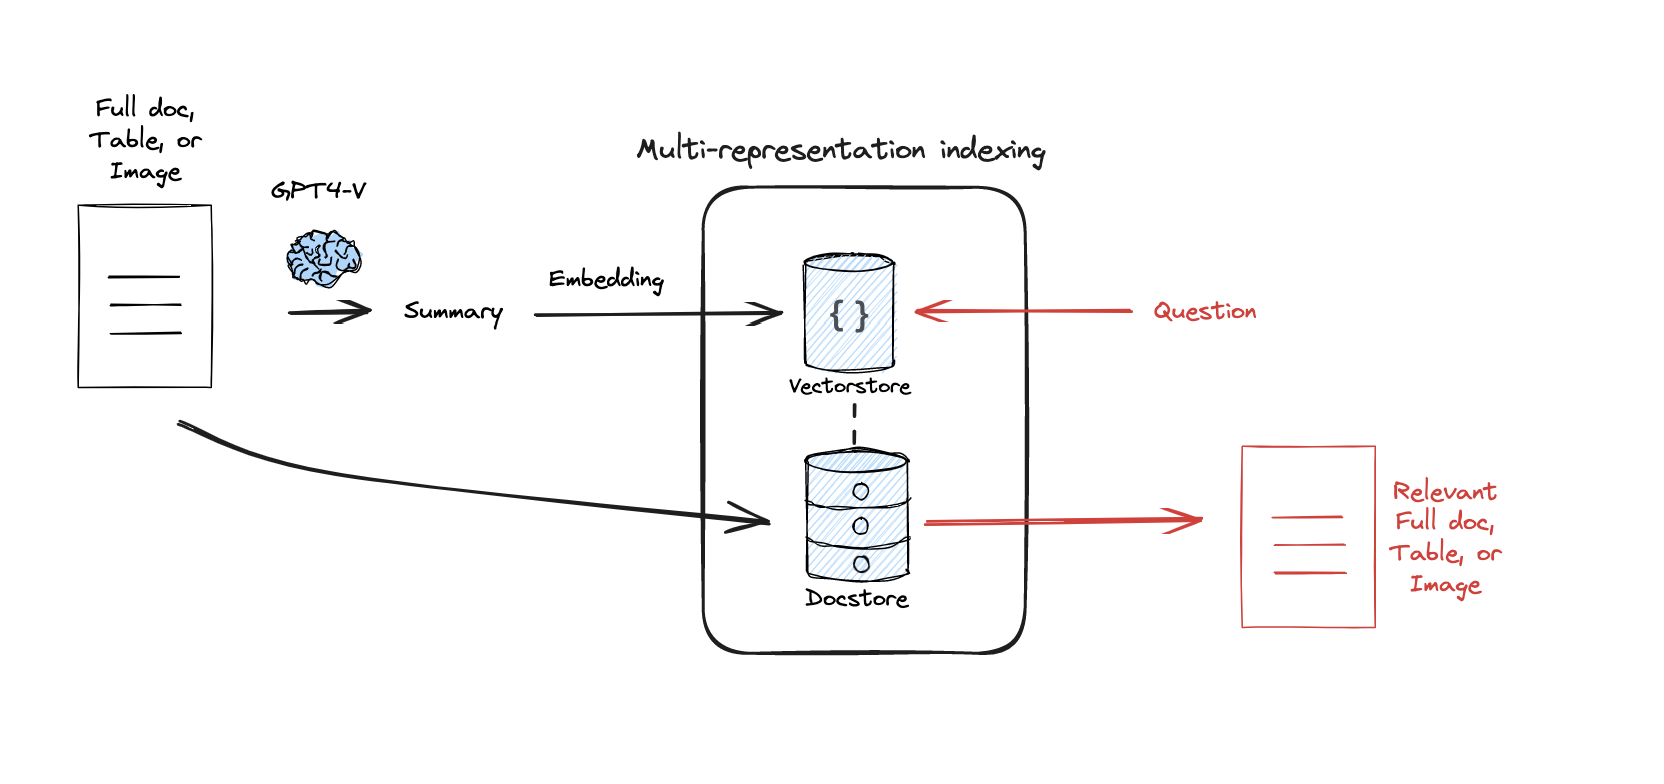

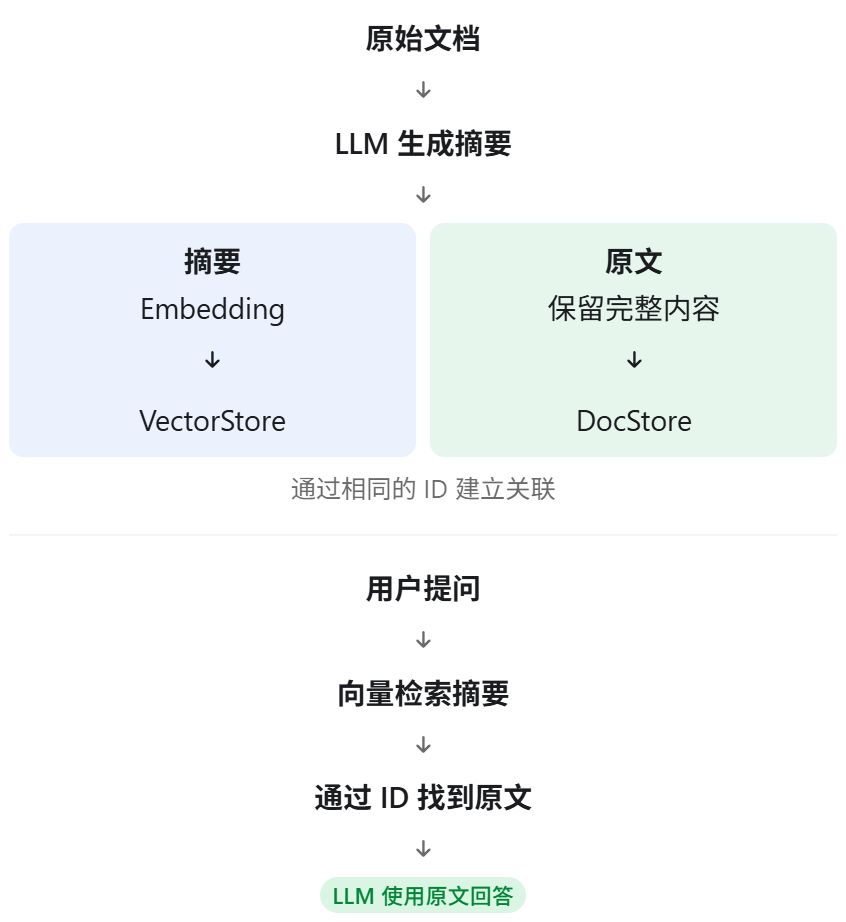
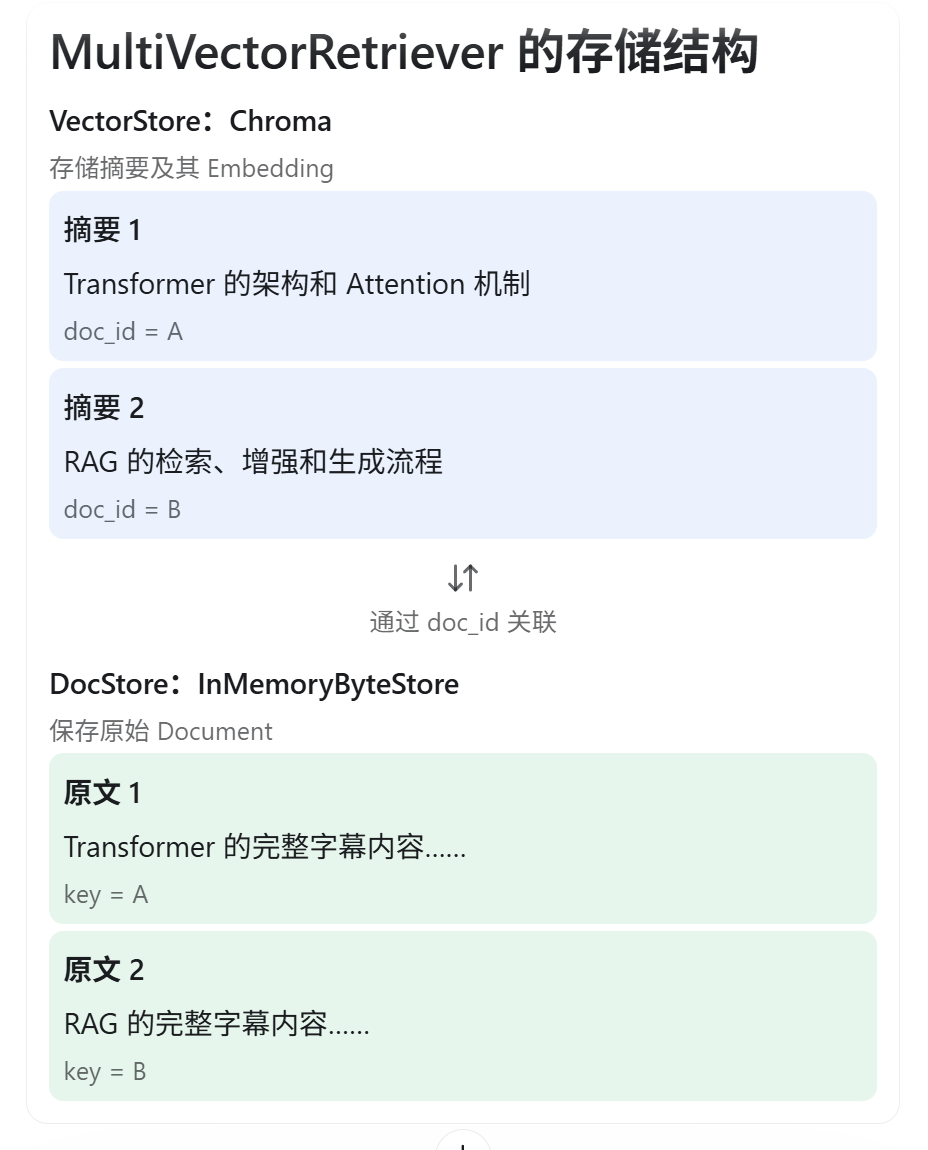
用户通过摘要找到摘要id，摘要id=文档id，找到完成文档


In [17]:
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

loader = WebBaseLoader("https://sherconan.github.io/ai-frontiers-cn/researchers/lilianweng/01-LLM%E9%A9%B1%E5%8A%A8%E7%9A%84%E8%87%AA%E4%B8%BB%E6%99%BA%E8%83%BD%E4%BD%93?utm_source=chatgpt.com")
docs = loader.load()

loader = WebBaseLoader("https://www.cnblogs.com/apachecn/p/18520569?utm_source=chatgpt.com")
docs.extend(loader.load())

In [18]:
print(type(docs))
print(len(docs))  # docs=[document1,document2]； document1包含page_content，metadata，id

<class 'list'>
2


## 1.用llm生成摘要


In [ ]:
import uuid

from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from rag_config import make_chat_model

chain = (
    {"doc": lambda x: x.page_content}  # 提取document对象的某个元素
    # from_template可以自动识别 key，不需要指定字段，他会自己检查
    | ChatPromptTemplate.from_template("总结下面的文档:\n\n{doc}")
    | make_chat_model(max_retries=0)
    | StrOutputParser()
)

# 一次处理多个输入。
# batch()：如批量处理多个输入.别对ist里的每个 Document 生成摘要
# {"max_concurrency": 5}字段：最多允许五个任务同时执行。
summaries = chain.batch(docs, {"max_concurrency": 5})
print(len(summaries))

## 2.创建摘要库，文件库

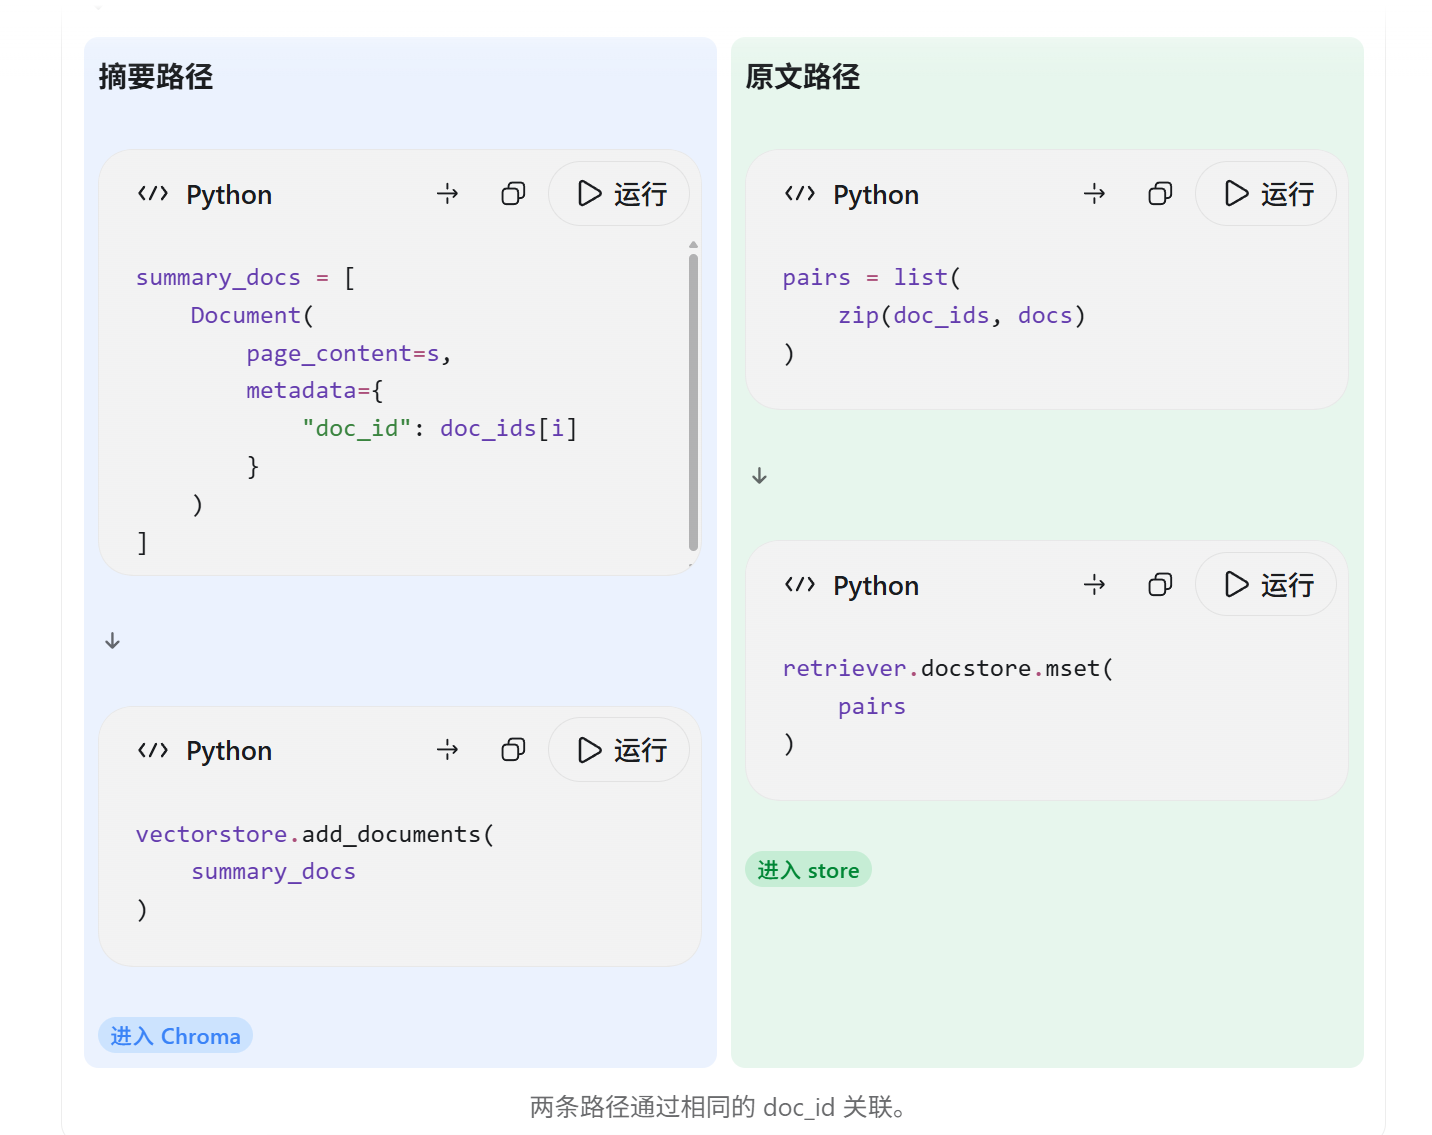

### store 原文
```py
retriever.docstore.mset(list(zip(doc_ids, docs)))
```
- docs是[document,],所以store不需要额外再创建doc对象了
- 在创建的时候就用的是doc_id

### vectorstore 摘要
```py
summary_docs = [
    Document(page_content=s, 
            metadata={id_key: doc_ids[i]})  
    for i, s in enumerate(summaries)
]
```
vectorstore是从llm生成的[message,]得来的。所以需要构建doc对象，同时用doc_ids[i]来作为自己的id



In [ ]:
from langchain_core.stores import InMemoryByteStore
from rag_config import make_embeddings
from langchain_chroma import Chroma
from langchain_classic.retrievers.multi_vector import MultiVectorRetriever

# Chroma（摘要向量库）
vectorstore = Chroma(collection_name="summaries", # 集合名称
                        embedding_function=make_embeddings())  #负责将摘要转换成向量

# DocStore（原文存储）
#创建了一个内存中的键值存储（Key-Value Store），一个空字典。
store = InMemoryByteStore()

id_key = "doc_id"  # 之后的id_key其实都是指"doc_id"

# 1.创建 MultiVectorRetriever
retriever = MultiVectorRetriever(
    vectorstore=vectorstore,
    byte_store=store, # 把 byte_store 包装成一个docstore
    id_key=id_key,   # 用doc_id把两个库联系起来
)

# 2.创建 doc_ids
# uuid.uuid4()：生成一个随机的唯一标识符，例如550e8400-e29b-41d4-a716-446655440000
# for _ :循环变量不需要使用。
doc_ids = [str(uuid.uuid4()) for _ in docs] #按docs的原有顺序生成id

# 3.创建doc对象，并把doc_ids添加到summaries中
summary_docs = [
    Document(page_content=s, 
            #实际是{"doc_id": doc_ids[i]}
            metadata={id_key: doc_ids[i]}) 
    for i, s in enumerate(summaries)
]

#对vectorstore操作，填充summaries
retriever.vectorstore.add_documents(summary_docs) 

# zip: 把两个list同位置的元素配对，把id和doc联系起来
# 把doc_ids添加到原文的document对象中
# mset：批量设置（存储）键值对，将多个 ID 和对应的原始 Document 批量存入 DocStore。
retriever.docstore.mset(list(zip(doc_ids, docs))) #对store操作，向里面填充原文数据

In [ ]:
# 测试一下能否在摘要库里面找到
query = "智能体的记忆"
# 由问题找到摘要
sub_docs = vectorstore.similarity_search(query,k=1)  #自动把query转化成向量，返回前k个最相似的

print(sub_docs[0].metadata["doc_id"])
print("长度",len(sub_docs))
print(sub_docs[0]) # 返回的是摘要

```text
retrieved_docs                 # list
    │
    └── retrieved_docs[0]      # Document
            │
            ├── page_content   # str
            │       │
            │       └── [0:500]  # 前500个字符
            │
            └── metadata       # dict


In [ ]:
query = "智能体的记忆"

retriever.search_kwargs = {"k": 1}  # 控制检索器参数，只返回一个结果

retrieved_docs = retriever.invoke(query)
# 取第一个结果的page_content的前500行
retrieved_docs[0].page_content[0:500]  # 返回的是原文

'\n\n\n\n\nLLM Powered Autonomous Agents | LLM 驱动的自主智能体 | AI 前沿精读\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nSkip to contentAI 前沿精读搜索文章K Main Navigation 首页✨ 每日精选海外实验室🧠 Anthropic (64)🤖 OpenAI (30)🔬 DeepMind (29)🦙 Meta AI (9)⚡ xAI / Grok (2)🇪🇺 Mistral AI (7)💚 NVIDIA (4)🤗 Hugging Face (2)🪟 Microsoft (1)中国 AI🦊 DeepSeek (11)🌙 Kimi / 月之暗面 (8)☁️ Qwen / 通义 (10)🇨🇳 MiniMax / 智谱 / 百川 (3)按主题🤖 Agent 构建🔒 安全与对齐🧪 推理能力🏗️ 工程实践🚀 模型发布与架构🕰️ 时间线特别专题📊 2026 Q1 大模型横评研究者 & 论文📜 基础论文精读 (6)🎓 Karpathy (7)📝 Lilian Weng (6)🛡️ Simon Willison (2'

完整的链路

In [33]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda,RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser
from rag_config import make_chat_model

retriever.search_kwargs = {"k": 1}

system="""
你是一个专业的ai助手,根据下面的资料回答问题。
如果参考资料中没有相关信息，请明确说明，不要编造答案。

参考资料:
{raw_doc}
"""

prompt=ChatPromptTemplate.from_messages(
    [
        ("system",system),
        ("human","{query}")
    ]
)

chain=(
    {
        "raw_doc":RunnableLambda(lambda x:retriever.invoke(x)[0].page_content),

        "query":RunnablePassthrough()
    }
    |prompt
    |make_chat_model(temperature=0)
    |StrOutputParser()
)

answer=chain.invoke("智能体的记忆是什么")
